In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import(
            mean_absolute_error,
            mean_squared_error,
            r2_score)

In [16]:
#step 1- load data
df=pd.read_csv("C:\Backup - Profile\linear_regression_demo_students.csv")
print(df)

   study_hours  marks
0            1     42
1            2     45
2            3     50
3            4     55
4            5     61
5            6     65
6            7     70
7            8     76
8            9     81
9           10     88


In [17]:
#step 2- identify x and y
#sample data
X= df[["study_hours"]]
y=df["marks"]

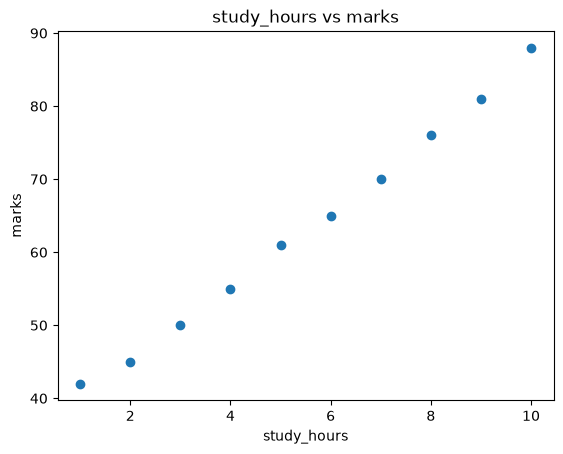

In [18]:
#step 3- plot the datas
plt.scatter(X,y)
plt.xlabel("study_hours")
plt.ylabel("marks")
plt.title("study_hours vs marks")
plt.show()

In [19]:
#step 4- split the data
X_train,X_test,y_train,y_test= train_test_split(X,y,test_size=0.2,random_state=42)

In [20]:
#step 5- create and train model
model= LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[5.11]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['study_hours']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,35.26
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [21]:
#step 6- find the equation
print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)

Slope: 5.112068965517242
Intercept: 35.25862068965517


In [22]:
#step 7-predict test data
y_pred=model.predict(pd.DataFrame(X_test))
comparison = pd.DataFrame({
    "Actual":y_test.values,
    "Predicted": y_pred})
print(comparison)

   Actual  Predicted
0      81  81.267241
1      45  45.482759


In [23]:
#step 8-evaluate
mae= mean_absolute_error(y_test, y_pred)
mse= mean_squared_error(y_test, y_pred)
rmse= np.sqrt(mse)
r2=r2_score(y_test, y_pred)
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R^2:",r2)

MAE: 0.375
MSE: 0.15223692033293615
RMSE: 0.39017549940114915
R^2: 0.9995301329619354


In [24]:
#step 9- predict for a new advertising spend
new_data=pd.DataFrame({"study_hours": [47]})
prediction= model.predict(new_data)
print("Predicted hours:", prediction[0])

Predicted hours: 275.5258620689655


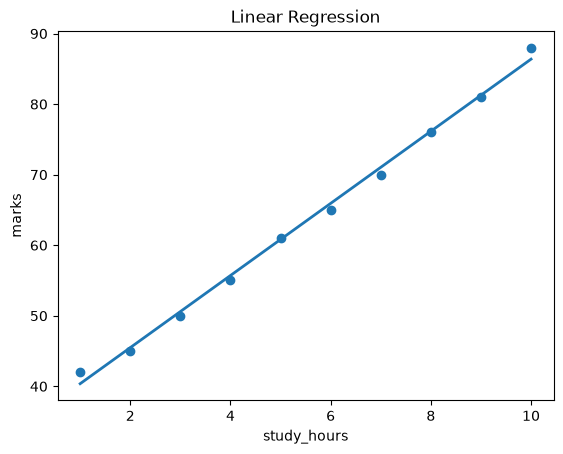

In [25]:
#step 10- plot the regression line
plt.scatter(X,y)
plt.plot(X,model.predict(X),linewidth=2)

plt.xlabel("study_hours")
plt.ylabel("marks")
plt.title("Linear Regression")

plt.show()